In [7]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(3)

In [8]:
#Gerando a Normal Zk

def Normal(mi,sigma2):
    u = np.random.uniform()
    u_2pi = 2*np.pi*u
    t = -np.log(u)
    x = np.sqrt(2*t)*np.cos(u_2pi)

    return sigma2*x + mi


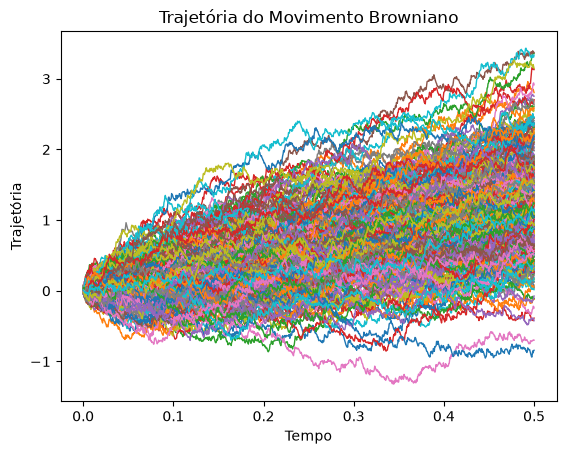

In [9]:
t = .5
n = 1000
dt = t/n
time = np.linspace(0,t,n)

simulacoes = 300
for i in range(simulacoes):
    x = 0
    trajetoria = []

    for k in range(n):
        x = x + np.sqrt(dt)*Normal(0,1)
        trajetoria.append(x)

    plt.plot(time, trajetoria, linewidth = 1)


plt.xlabel('Tempo')
plt.ylabel('Trajetória')
plt.title('Trajetória do Movimento Browniano')
plt.show()

In [10]:
def normal(x,mi,sigma2):
    num = np.exp(-(x-mi)**2/(2*sigma2))
    den = np.sqrt(2*sigma2*np.pi)
    return num/den

In [11]:
def p(x):
    return normal(x,-2,1)/2 + normal(x,2,1)/2

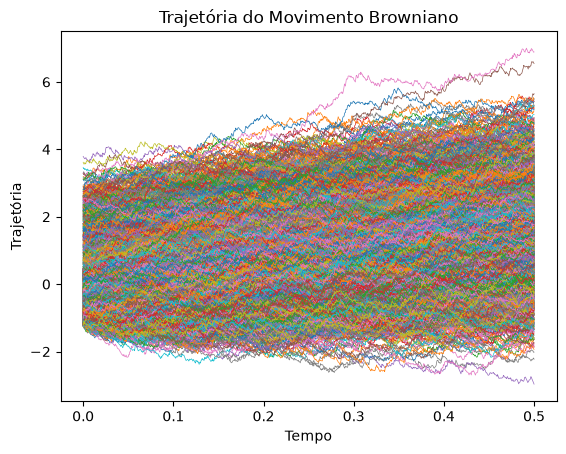

In [14]:
def a(x):
    h = 0.00000001
    return (np.log(p(x + h)) - np.log(p(x - h))) / (2 * h)

b = np.sqrt(2)

t = .5
n = 1000
dt = t/n
time = np.linspace(0,t,n)

simulacoes = 2000
valores_finais = []
for i in range(simulacoes):
    x = Normal(0,1)
    trajetoria = []

    for k in range(n):
        x = x + b*np.sqrt(dt)*Normal(0,1) + a(x)*dt
        trajetoria.append(x)
    valores_finais.append(x)
    plt.plot(time, trajetoria, linewidth = .5)


plt.xlabel('Tempo')
plt.ylabel('Trajetória')
plt.title('Trajetória do Movimento Browniano')
plt.show()


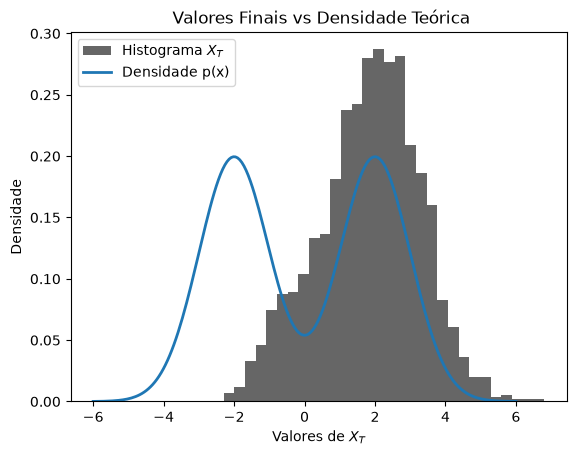

In [13]:
# Histograma dos valores finais
plt.hist(valores_finais, bins=30, density=True, alpha=0.6, color='black', label='Histograma $X_T$')

# Criando um eixo x contínuo para desenhar a curva teórica da densidade p(x)
eixo_x = np.linspace(-6, 6, 200)
plt.plot(eixo_x, p(eixo_x), lw=2, label='Densidade p(x)')

plt.xlabel('Valores de $X_T$')
plt.ylabel('Densidade')
plt.title(' Valores Finais vs Densidade Teórica')
plt.legend()

plt.show()